In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
file=r"D:\dl ass prac\intel_6000.npz"

In [3]:
df=np.load('intel_6000.npz')

In [4]:
df.files

['images', 'labels', 'classes']

In [5]:
X=df['images']/255
y=df['labels']
classes=df['classes']

In [6]:
X.shape

(6000, 64, 64, 3)

In [7]:
y.shape

(6000,)

In [8]:
classes.shape

(6,)

In [9]:
num_classes=len(classes)
num_classes

6

In [10]:
from sklearn.model_selection import train_test_split
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import MaxPooling2D,Conv2D,Dense,Flatten,Input,Dropout
from tensorflow.keras.utils import to_categorical

In [11]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2)

In [12]:
X_train.shape

(4800, 64, 64, 3)

In [13]:
X_test.shape

(1200, 64, 64, 3)

In [14]:
y_train.shape

(4800,)

In [15]:
y_train_cat=to_categorical(y_train,num_classes)
y_test_cat=to_categorical(y_test,num_classes)

In [16]:
y_train_cat.shape

(4800, 6)

In [17]:
y_train_cat

array([[0., 0., 0., 0., 0., 1.],
       [0., 0., 1., 0., 0., 0.],
       [0., 0., 1., 0., 0., 0.],
       ...,
       [0., 0., 0., 1., 0., 0.],
       [0., 0., 1., 0., 0., 0.],
       [0., 0., 0., 0., 0., 1.]], shape=(4800, 6))

In [18]:
model=Sequential([
    Input(shape=(64,64,3)),
    Conv2D(32,(3,3),activation='relu'),
    MaxPooling2D(2,2),
    Flatten(),
    Dense(128,activation='relu'),
    Dropout(0.2),
    Dense(num_classes,activation='softmax')
])
          
          

In [19]:
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [20]:
model.fit(X_train,y_train_cat,epochs=5,batch_size=128)

Epoch 1/5
38/38 ━━━━━━━━━━━━━━━━━━━━ 10s 206ms/step - accuracy: 0.3500 - loss: 1.9939
Epoch 2/5
38/38 ━━━━━━━━━━━━━━━━━━━━ 10s 200ms/step - accuracy: 0.5644 - loss: 1.1598
Epoch 3/5
38/38 ━━━━━━━━━━━━━━━━━━━━ 11s 205ms/step - accuracy: 0.6369 - loss: 0.9844
Epoch 4/5
38/38 ━━━━━━━━━━━━━━━━━━━━ 10s 198ms/step - accuracy: 0.6769 - loss: 0.8715
Epoch 5/5
38/38 ━━━━━━━━━━━━━━━━━━━━ 8s 208ms/step - accuracy: 0.7240 - loss: 0.7728


In [21]:
loss,accuracy=model.evaluate(X_test,y_test_cat)

38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - accuracy: 0.6967 - loss: 0.8564


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 146ms/step
ACtual:  sea
Predicted: mountain


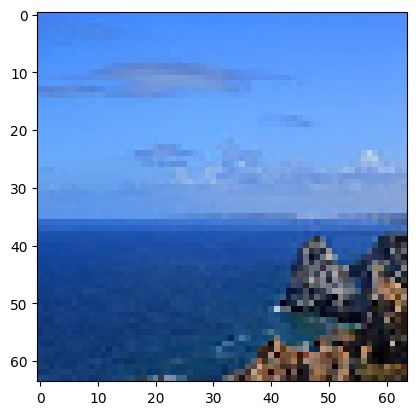

In [22]:
plt.imshow(X_test[5])
i=5
pred=model.predict(X_test[i:i+1])
print("ACtual: ",classes[np.argmax(y_test_cat[i])])
print("Predicted:",classes[np.argmax(pred)])